**DATA LOADING**

In [25]:
%pip install matplotlib pandas numpy seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [26]:
 pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


In [28]:
import pandas as pd

url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"

df = pd.read_csv(url)

df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [29]:
from pathlib import Path

data_dir = Path.cwd().parent / "data"
data_dir.mkdir(exist_ok=True)

df.to_csv(data_dir / "insurance.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


**EDA**

In [30]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

Dataset shape: (1338, 7)

Missing values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB

Statistical summary:


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [31]:
df.shape

(1338, 7)

In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [33]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

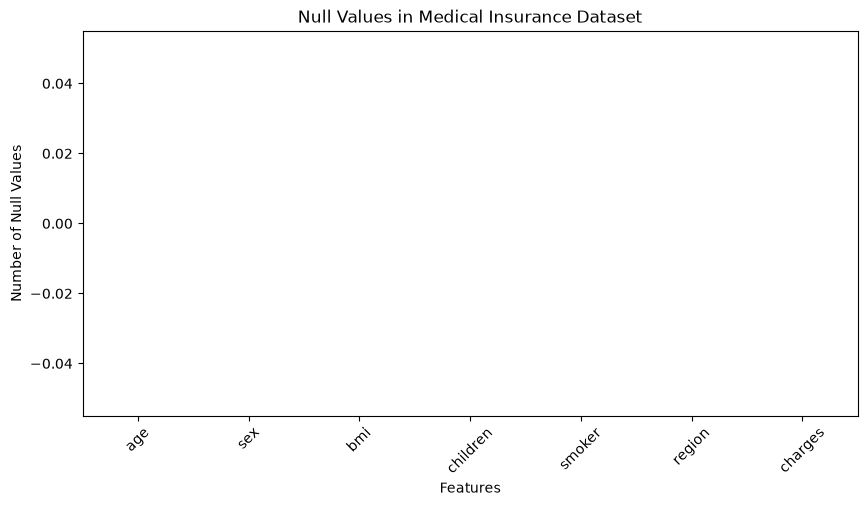

In [34]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

df.isnull().sum().plot(kind='bar', color='skyblue')

plt.xlabel("Features")
plt.ylabel("Number of Null Values")
plt.title("Null Values in Medical Insurance Dataset")
plt.xticks(rotation=45)
plt.show()

In [35]:
df.duplicated().sum()

np.int64(1)

In [36]:
df = df.drop_duplicates().reset_index(drop=True)

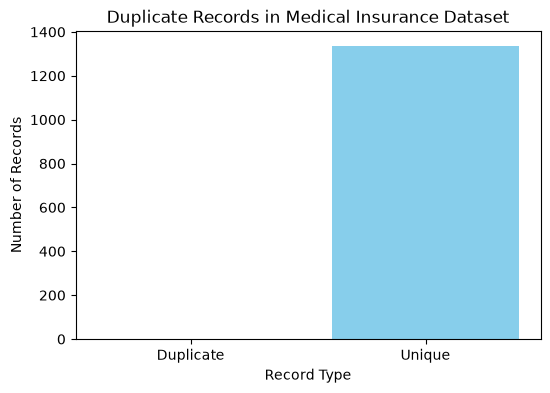

In [37]:
import matplotlib.pyplot as plt

duplicate = df.duplicated().sum()
unique = len(df) - duplicate

plt.figure(figsize=(6, 4))

plt.bar(['Duplicate', 'Unique'], [duplicate, unique],
        color=['red', 'skyblue'])

plt.xlabel('Record Type')
plt.ylabel('Number of Records')
plt.title('Duplicate Records in Medical Insurance Dataset')

plt.show()

In [38]:
df.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


**Visualize medical charges**

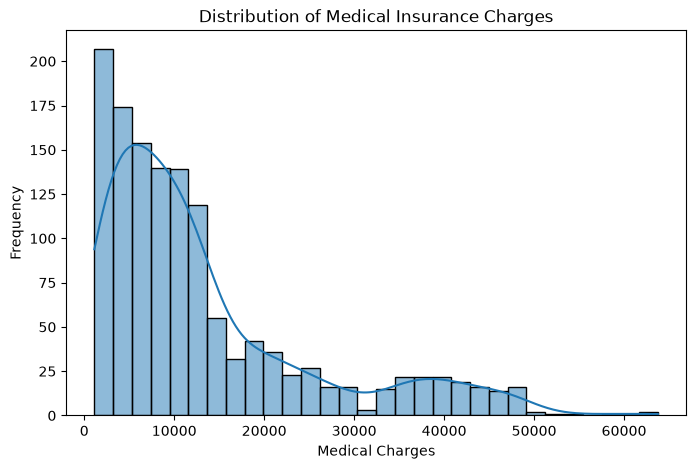

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(df["charges"], bins=30, kde=True)
plt.title("Distribution of Medical Insurance Charges")
plt.xlabel("Medical Charges")
plt.ylabel("Frequency")
plt.show()

**Plots of each column**

**Plot 1 — Age distribution**

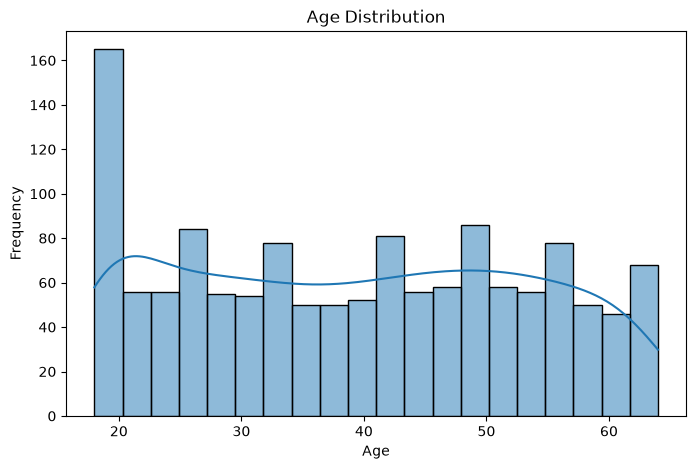

In [40]:
plt.figure(figsize=(8, 5))
sns.histplot(df["age"], bins=20, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

**Plot 2 — Sex distribution**

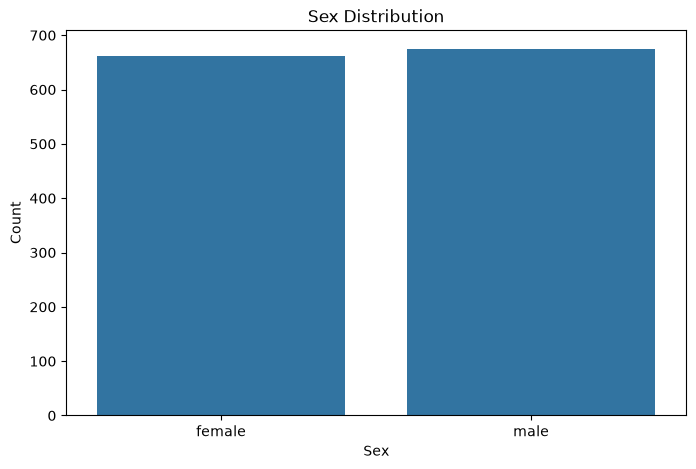

In [41]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="sex")
plt.title("Sex Distribution")
plt.xlabel("Sex")
plt.ylabel("Count")
plt.show()

**Plot 3 — BMI distribution**

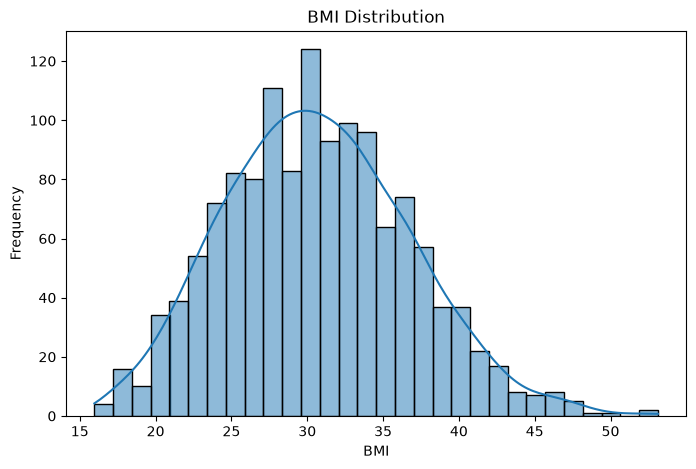

In [42]:
plt.figure(figsize=(8, 5))
sns.histplot(df["bmi"], bins=30, kde=True)
plt.title("BMI Distribution")
plt.xlabel("BMI")
plt.ylabel("Frequency")
plt.show()

**Plot 4 — Children distribution**

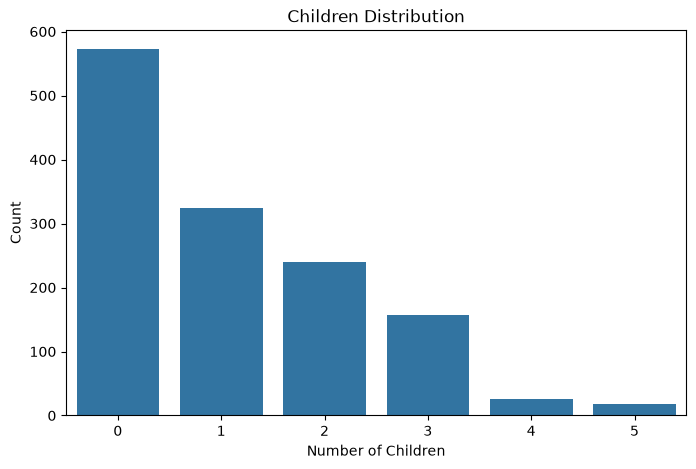

In [43]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="children")
plt.title("Children Distribution")
plt.xlabel("Number of Children")
plt.ylabel("Count")
plt.show()

**Plot 5 — Smoker distribution**

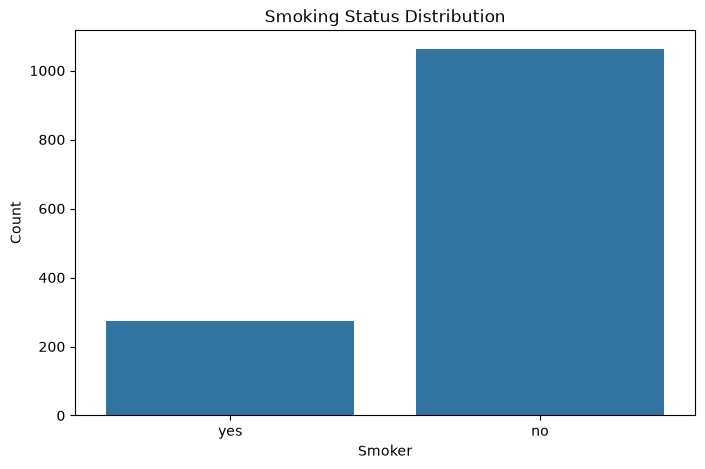

In [44]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="smoker")
plt.title("Smoking Status Distribution")
plt.xlabel("Smoker")
plt.ylabel("Count")
plt.show()

**Plot 6 — Region distribution**

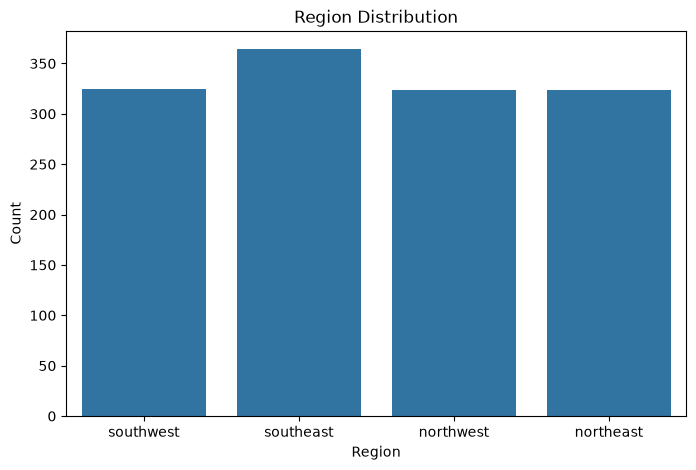

In [45]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="region")
plt.title("Region Distribution")
plt.xlabel("Region")
plt.ylabel("Count")
plt.show()

**Plot 7 — Medical charges distribution**

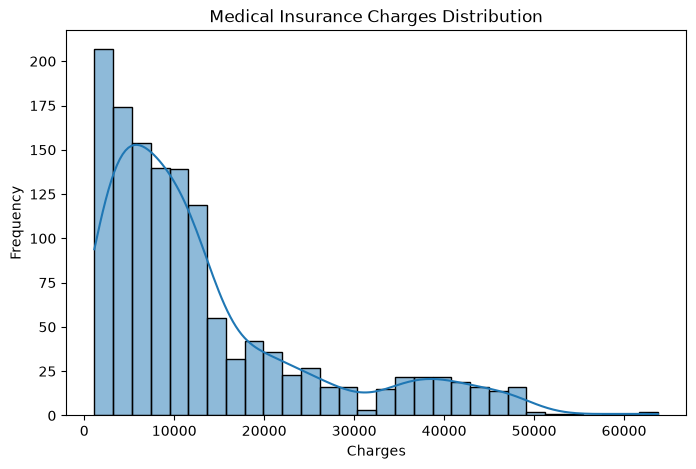

In [46]:
plt.figure(figsize=(8, 5))
sns.histplot(df["charges"], bins=30, kde=True)
plt.title("Medical Insurance Charges Distribution")
plt.xlabel("Charges")
plt.ylabel("Frequency")
plt.show()

**Analyze smoking status vs charges**

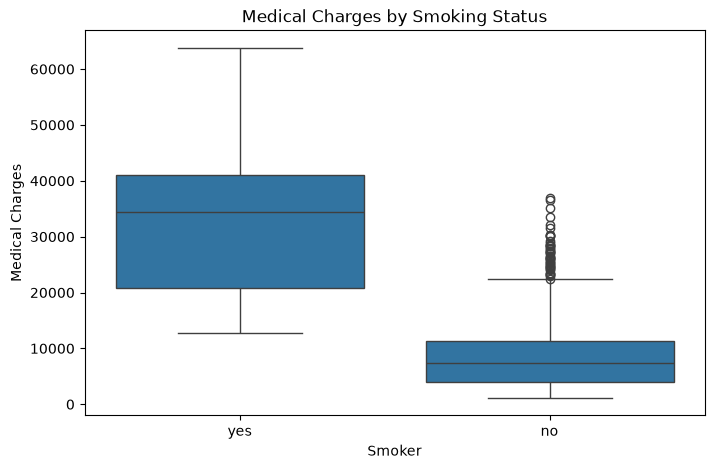

In [47]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="smoker", y="charges")
plt.title("Medical Charges by Smoking Status")
plt.xlabel("Smoker")
plt.ylabel("Medical Charges")
plt.show()

**Plots for Analyze smoking status vs charges**

**1. Age vs Charges**

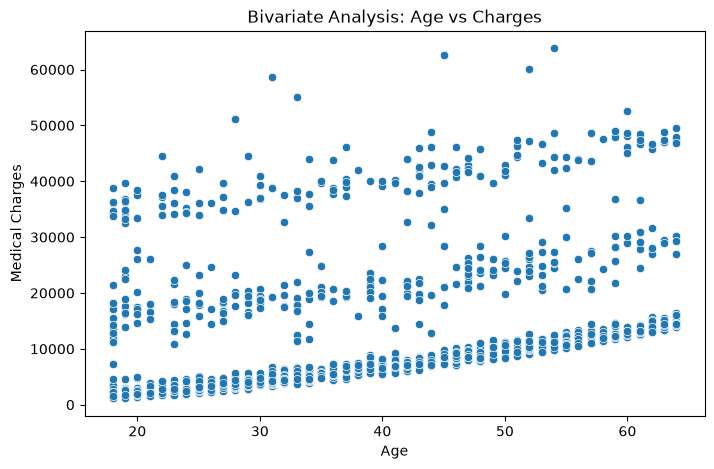

In [48]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="age", y="charges")
plt.title("Bivariate Analysis: Age vs Charges")
plt.xlabel("Age")
plt.ylabel("Medical Charges")
plt.show()

**2. Sex vs Charges**

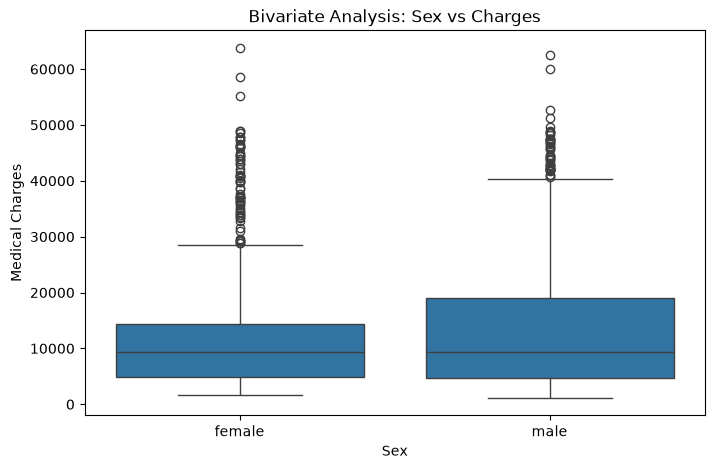

In [49]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="sex", y="charges")
plt.title("Bivariate Analysis: Sex vs Charges")
plt.xlabel("Sex")
plt.ylabel("Medical Charges")
plt.show()

**3. BMI vs Charges**

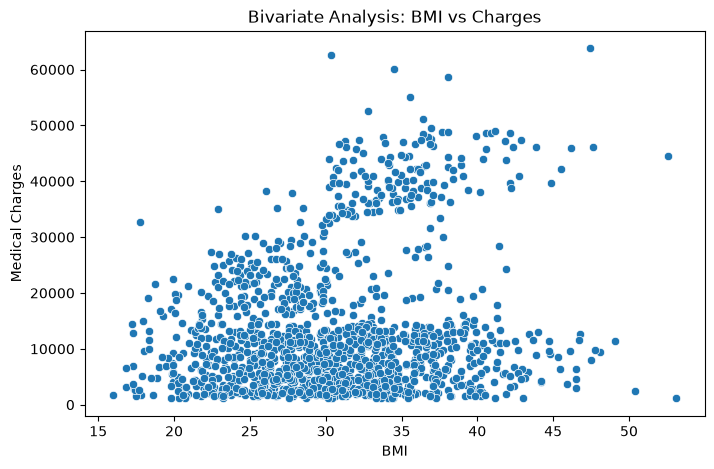

In [50]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="bmi", y="charges")
plt.title("Bivariate Analysis: BMI vs Charges")
plt.xlabel("BMI")
plt.ylabel("Medical Charges")
plt.show()

**4. Children vs Charges**

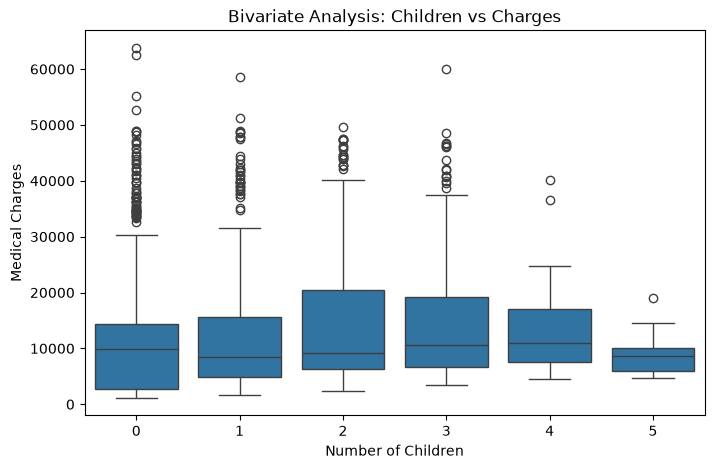

In [51]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="children", y="charges")
plt.title("Bivariate Analysis: Children vs Charges")
plt.xlabel("Number of Children")
plt.ylabel("Medical Charges")
plt.show()

**5. Smoker vs Charges**

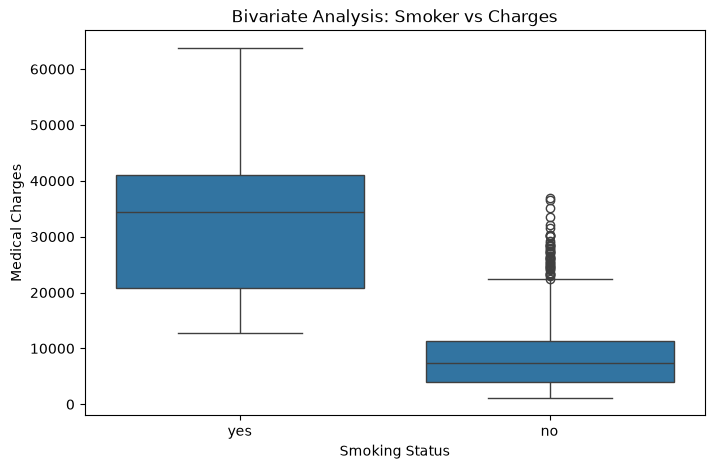

In [52]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="smoker", y="charges")
plt.title("Bivariate Analysis: Smoker vs Charges")
plt.xlabel("Smoking Status")
plt.ylabel("Medical Charges")
plt.show()

**6. Region vs Charges**

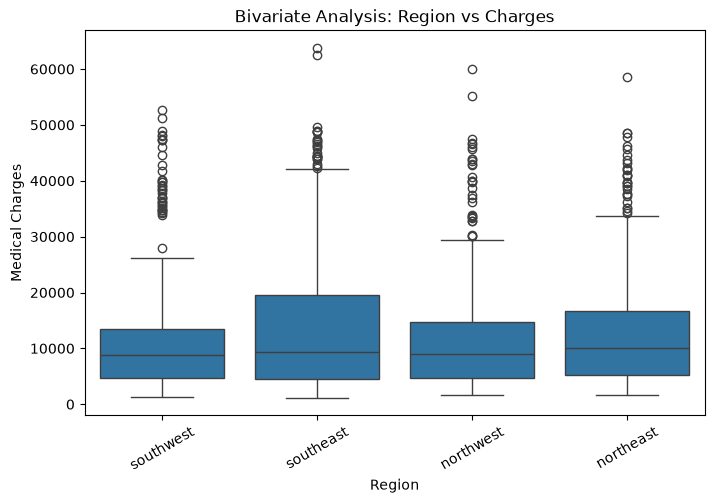

In [53]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="region", y="charges")
plt.title("Bivariate Analysis: Region vs Charges")
plt.xlabel("Region")
plt.ylabel("Medical Charges")
plt.xticks(rotation=30)
plt.show()

**Correlation heatmap**

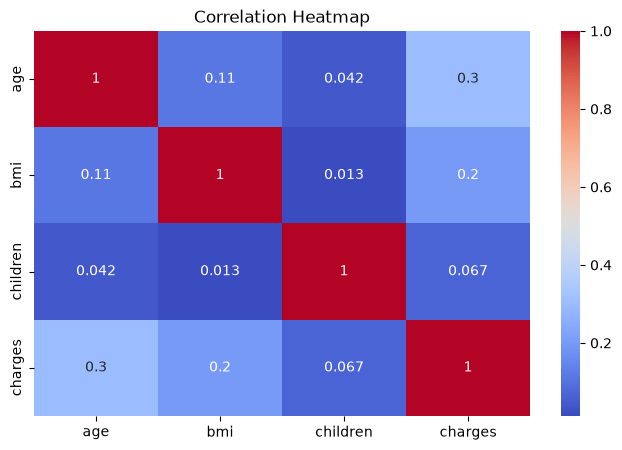

In [54]:
plt.figure(figsize=(8, 5))
sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm"
)
plt.title("Correlation Heatmap")
plt.show()

**Data Preprocessing for Linear Regression**

**#1.Task#**

**1.1 Separate input features and target**

In [55]:

X = df.drop(columns=["charges"])
y = df["charges"]

print("X shape:", X.shape)
print("y shape:", y.shape)



X shape: (1337, 6)
y shape: (1337,)


**1.2 Split the dataset into training and testing sets**

In [56]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)



Training features: (1069, 6)
Testing features: (268, 6)


**1.3 Create the preprocessing transformer**

In [59]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_cols = ["sex", "smoker", "region"]
numerical_cols = ["age", "bmi", "children"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

**1.4 Apply Preprocessing**

In [61]:
preprocessor.fit(X_train)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [58]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Processed Training Shape: (1069, 11)
Processed Testing Shape: (268, 11)


**1.5 Check the processed feature names**

In [62]:
feature_names = preprocessor.get_feature_names_out()

print("Processed Feature Names:")
print(feature_names)

Processed Feature Names:
['num__age' 'num__bmi' 'num__children' 'cat__sex_female' 'cat__sex_male'
 'cat__smoker_no' 'cat__smoker_yes' 'cat__region_northeast'
 'cat__region_northwest' 'cat__region_southeast' 'cat__region_southwest']


**#2. Build and Train Linear Regression#**

**2.1 Import Linear Regression**

In [63]:
from sklearn.linear_model import LinearRegression

**2.2 Create the model**

In [64]:
model = LinearRegression()

**2.3 Train the model**

In [65]:
model.fit(X_train_processed, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


**2.4 Predict medical insurance charges**

In [66]:
y_pred = model.predict(X_test_processed)

print("First 10 Predicted Charges:")
print(y_pred[:10])

First 10 Predicted Charges:
[ 8143.69388412  5737.11568259 14369.31487618 31745.51363586
  8962.38665706 13149.72235307 30446.76067941  1453.28881259
 10633.01840233 11318.94379361]


**2.5 Compare actual vs predicted charges**

In [67]:
import pandas as pd

results = pd.DataFrame({
    "Actual Charges": y_test.to_numpy(),
    "Predicted Charges": y_pred
})

display(results.head(10))

,Actual Charges,Predicted Charges
0,8688.85885,8143.693884
1,5708.86700,5737.115683
2,11436.73815,14369.314876
3,38746.35510,31745.513636
4,4463.20510,8962.386657
5,9304.70190,13149.722353
6,38511.62830,30446.760679
7,2150.46900,1453.288813
8,7345.72660,10633.018402
9,10264.44210,11318.943794


**2.6 Visualize actual vs predicted charges**

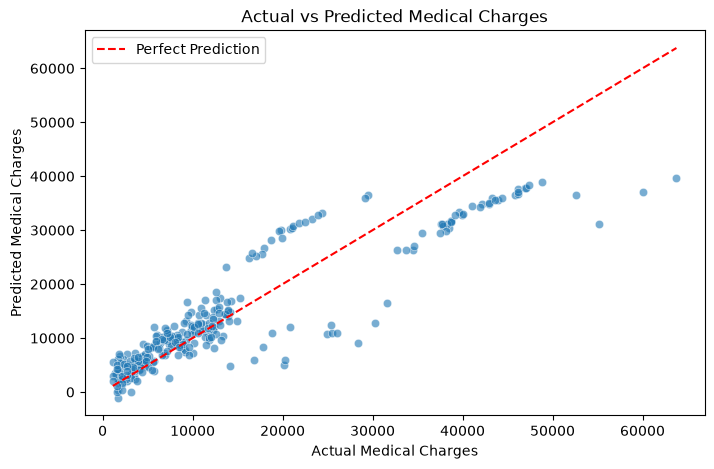

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=y_test,
    y=y_pred,
    alpha=0.6
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Medical Charges")
plt.ylabel("Predicted Medical Charges")
plt.title("Actual vs Predicted Medical Charges")
plt.legend()
plt.show()

**#3. Linear Regression Model Evaluation#**

**3.1 Import evaluation metrics**

In [69]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

**3.2 Calculate all four metrics**

In [70]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Linear Regression Evaluation Results")
print("------------------------------------")
print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

Linear Regression Evaluation Results
------------------------------------
MAE  : 4177.05
MSE  : 35478020.68
RMSE : 5956.34
R²   : 0.8069


**3.3 Understand the metrics**

**MAE**

Mean Absolute Error
Measures the average absolute difference between actual and predicted charges.
Example: MAE = 4,000 means predictions are off by about 4,000 currency units on average.

**MSE**

Mean Squared Error
Squares prediction errors before averaging, so large mistakes receive a greater penalty. Its units are squared currency units.

**RMSE**

Root Mean Squared Error
The square root of MSE. It's in the same units as medical charges and is more sensitive to large errors than MAE.

**R²**

R-Squared Score
Measures how well the model explains variation in medical charges.
For example, R² = 0.75 means the model explains approximately 75% of the variation in the test-set charges.

**3.4 Visualize prediction errors**

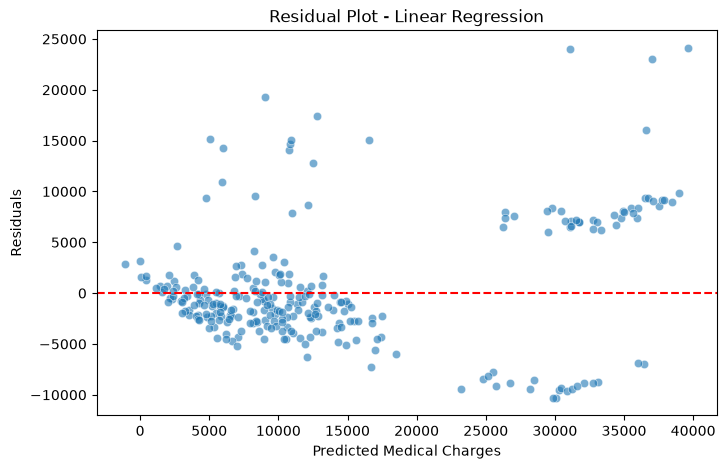

In [71]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=y_pred,
    y=residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted Medical Charges")
plt.ylabel("Residuals")
plt.title("Residual Plot - Linear Regression")
plt.show()

**#4 Review Linear Regression Results#**

In [72]:
print("Linear Regression Performance")
print("-----------------------------")
print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

Linear Regression Performance
-----------------------------
MAE  : 4177.05
MSE  : 35478020.68
RMSE : 5956.34
R²   : 0.8069


In [73]:
print(
    f"The Linear Regression model achieved an R² score of {r2:.4f}. "
    f"The average absolute prediction error was {mae:.2f}, "
    f"and the RMSE was {rmse:.2f}."
)

The Linear Regression model achieved an R² score of 0.8069. The average absolute prediction error was 4177.05, and the RMSE was 5956.34.


**#5 Begin Logistic Regression Classification#**

**5.1 Separate features and target**

**Logistic Regression — Data Preprocessing**

In [74]:
X_cls = df.drop(columns=["smoker"])
y_cls = df["smoker"]

print("Classification Features:", X_cls.shape)
print("Classification Target:", y_cls.shape)
print("\nTarget Distribution:")
print(y_cls.value_counts())

Classification Features: (1337, 6)
Classification Target: (1337,)

Target Distribution:
smoker
no     1063
yes     274
Name: count, dtype: int64


**5.2 Encode the target variable**

In [75]:
y_cls = y_cls.map({
    "no": 0,
    "yes": 1
})

print(y_cls.value_counts())

smoker
0    1063
1     274
Name: count, dtype: int64


**5.3 Split classification data**

In [76]:
from sklearn.model_selection import train_test_split

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls,
    y_cls,
    test_size=0.2,
    random_state=42,
    stratify=y_cls
)

print("Training Shape:", X_train_cls.shape)
print("Testing Shape:", X_test_cls.shape)

Training Shape: (1069, 6)
Testing Shape: (268, 6)


**5.4 Create classification preprocessing transformer**

In [77]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

categorical_cols_cls = ["sex", "region"]
numerical_cols_cls = ["age", "bmi", "children", "charges"]

preprocessor_cls = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols_cls),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols_cls)
    ]
)

**5.5 Apply preprocessing**

In [ ]:
X_train_cls_processed = preprocessor_cls.fit_transform(X_train_cls)
X_test_cls_processed = preprocessor_cls.transform(X_test_cls)

print("Processed Training:", X_train_cls_processed.shape)
print("Processed Testing:", X_test_cls_processed.shape)

**#6. Feature Coefficient Analysis#**

**6.1 Extract feature coefficients**

In [78]:
import pandas as pd

feature_names = preprocessor.get_feature_names_out()

coefficients_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": model.coef_
})

display(coefficients_df)

,Feature,Coefficient
0,num__age,3472.975553
1,num__bmi,1927.828251
2,num__children,636.501185
3,cat__sex_female,50.771027
4,cat__sex_male,-50.771027
5,cat__smoker_no,-11538.882296
6,cat__smoker_yes,11538.882296
7,cat__region_northeast,472.455206
8,cat__region_northwest,80.693751
9,cat__region_southeast,-366.464410


**6.2 Sort coefficients by magnitude**

In [79]:
coefficients_df["Absolute Coefficient"] = (
    coefficients_df["Coefficient"].abs()
)

coefficients_df = coefficients_df.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

display(coefficients_df)

,Feature,Coefficient,Absolute Coefficient
6,cat__smoker_yes,11538.882296,11538.882296
5,cat__smoker_no,-11538.882296,11538.882296
0,num__age,3472.975553,3472.975553
1,num__bmi,1927.828251,1927.828251
2,num__children,636.501185,636.501185
7,cat__region_northeast,472.455206,472.455206
9,cat__region_southeast,-366.464410,366.464410
10,cat__region_southwest,-186.684546,186.684546
8,cat__region_northwest,80.693751,80.693751
4,cat__sex_male,-50.771027,50.771027


**6.3 Visualize the coefficients**

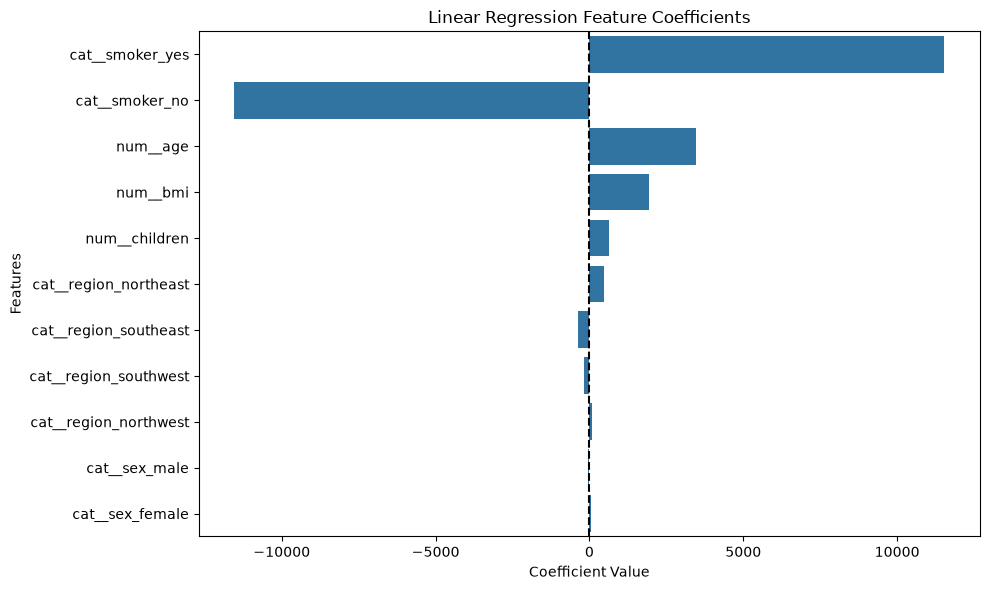

In [80]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=coefficients_df,
    x="Coefficient",
    y="Feature"
)

plt.axvline(
    x=0,
    color="black",
    linestyle="--"
)

plt.title("Linear Regression Feature Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

**6.4 Display the model intercept**

In [81]:
print("Model Intercept:", model.intercept_)

Model Intercept: 19963.60825899217


## Linear Regression — Final Conclusion

The Medical Insurance Charges Prediction project was developed using Linear Regression to estimate insurance charges based on age, sex, BMI, number of children, smoking status, and region.

The dataset was explored using univariate and bivariate analysis, cleaned, and preprocessed using StandardScaler and OneHotEncoder. The data was divided into training and testing sets using an 80:20 ratio.

### Model Performance

| Evaluation Metric | Result |
|---|---:|
| MAE | 4,177.05 |
| MSE | 35,478,020.68 |
| RMSE | 5,956.34 |
| R² Score | 0.8069 |

The R² score indicates that the model explains approximately 80.69% of the variation in insurance charges within the test dataset.

### Feature Analysis

The coefficient analysis revealed that smoking status has a particularly strong association with predicted insurance charges. Age and BMI also showed substantial positive associations, while sex and region had relatively smaller coefficients.

### Final Observation

The Linear Regression model provides a useful baseline for predicting medical insurance charges. Although it explains a substantial portion of the variation, prediction errors remain, indicating opportunities for future improvements.

Overall, the project demonstrates the application of exploratory data analysis, preprocessing, Linear Regression, prediction, model evaluation, and coefficient interpretation.

# Logistic Regression Classification

In [82]:
# Step 1.1 - Separate features and target

X_cls = df.drop(columns=["smoker"])
y_cls = df["smoker"]

print("Input Features:", X_cls.shape)
print("Target:", y_cls.shape)

print("\nSmoking Status Distribution:")
print(y_cls.value_counts())

Input Features: (1337, 6)
Target: (1337,)

Smoking Status Distribution:
smoker
no     1063
yes     274
Name: count, dtype: int64


In [83]:
# Step 1.2 - Encode target variable

y_cls = y_cls.map({
    "no": 0,
    "yes": 1
})

print("Encoded Target Distribution:")
print(y_cls.value_counts())

print("\nMissing Values:", y_cls.isnull().sum())

Encoded Target Distribution:
smoker
0    1063
1     274
Name: count, dtype: int64

Missing Values: 0


In [84]:
# Step 1.3 - Train/Test Split

from sklearn.model_selection import train_test_split

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls,
    y_cls,
    test_size=0.2,
    random_state=42,
    stratify=y_cls
)

print("Training Features:", X_train_cls.shape)
print("Testing Features:", X_test_cls.shape)

print("Training Target:", y_train_cls.shape)
print("Testing Target:", y_test_cls.shape)

Training Features: (1069, 6)
Testing Features: (268, 6)
Training Target: (1069,)
Testing Target: (268,)


In [85]:
# Step 1.4 - Classification Preprocessing

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Categorical features
categorical_cols_cls = ["sex", "region"]

# Numerical features
numerical_cols_cls = ["age", "bmi", "children", "charges"]

# Create preprocessing transformer
preprocessor_cls = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols_cls),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols_cls)
    ]
)

print("Classification preprocessor created successfully!")

Classification preprocessor created successfully!


In [86]:
# Step 1.5 - Apply Preprocessing

# Fit and transform training data
X_train_cls_processed = preprocessor_cls.fit_transform(X_train_cls)

# Transform testing data
X_test_cls_processed = preprocessor_cls.transform(X_test_cls)

# Check processed data shapes
print("Processed Training Shape:", X_train_cls_processed.shape)
print("Processed Testing Shape:", X_test_cls_processed.shape)

Processed Training Shape: (1069, 10)
Processed Testing Shape: (268, 10)


# Step 2 — Train the Logistic Regression Model

In [87]:
# Step 2.1 - Train Logistic Regression Model

from sklearn.linear_model import LogisticRegression

# Create the model
log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
log_model.fit(X_train_cls_processed, y_train_cls)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [88]:
# Step 2.2 - Predict Smoking Status

# Predict on testing data
y_pred_cls = log_model.predict(X_test_cls_processed)

# Compare actual and predicted values
import pandas as pd

comparison_cls = pd.DataFrame({
    "Actual": y_test_cls.to_numpy(),
    "Predicted": y_pred_cls
})

print("Actual vs Predicted Smoking Status:")
print(comparison_cls.head(10))

Actual vs Predicted Smoking Status:
   Actual  Predicted
0       0          0
1       0          0
2       1          1
3       1          0
4       0          0
5       0          0
6       0          0
7       0          0
8       0          0
9       0          0


In [89]:
# Step 3.1 - Classification Evaluation Metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test_cls, y_pred_cls)
precision = precision_score(y_test_cls, y_pred_cls)
recall = recall_score(y_test_cls, y_pred_cls)
f1 = f1_score(y_test_cls, y_pred_cls)

print("Logistic Regression Evaluation Results")
print("--------------------------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

Logistic Regression Evaluation Results
--------------------------------------
Accuracy : 0.9627
Precision: 0.9245
Recall   : 0.8909
F1 Score : 0.9074


Confusion Matrix:
[[209   4]
 [  6  49]]


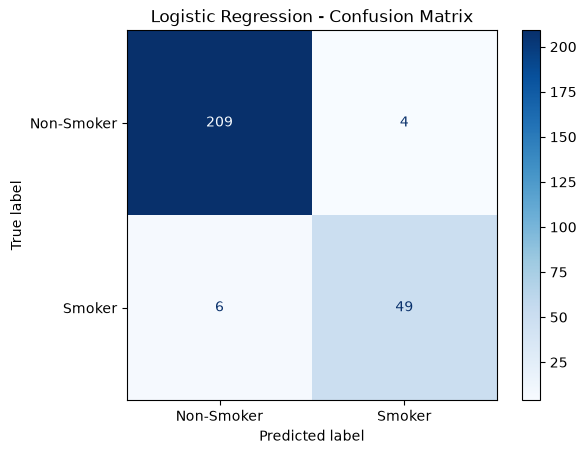

In [90]:
# Step 3.2 - Confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm = confusion_matrix(y_test_cls, y_pred_cls)

print("Confusion Matrix:")
print(cm)

# Visualize confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Smoker", "Smoker"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [91]:
# Step 3.3 - Classification Report

from sklearn.metrics import classification_report

print("Logistic Regression Classification Report")
print("-----------------------------------------")

print(
    classification_report(
        y_test_cls,
        y_pred_cls,
        target_names=["Non-Smoker", "Smoker"]
    )
)

Logistic Regression Classification Report
-----------------------------------------
              precision    recall  f1-score   support

  Non-Smoker       0.97      0.98      0.98       213
      Smoker       0.92      0.89      0.91        55

    accuracy                           0.96       268
   macro avg       0.95      0.94      0.94       268
weighted avg       0.96      0.96      0.96       268



# Step 4 — Write the Final Classification Conclusion

## Logistic Regression Classification — Conclusion

### Objective
The objective of this classification task was to predict whether an individual is a smoker or non-smoker using the Medical Insurance dataset.

### Model Development
- Used Logistic Regression for binary classification.
- Encoded the target variable: Non-Smoker = 0 and Smoker = 1.
- Applied StandardScaler to numerical features and OneHotEncoder to categorical features.
- Split the dataset into 80% training and 20% testing data using stratified sampling.

### Model Performance

| Evaluation Metric | Result |
|---|---|
| Accuracy | 96.27% |
| Precision (Smoker) | 92.45% |
| Recall (Smoker) | 89.09% |
| F1 Score (Smoker) | 90.74% |

### Confusion Matrix Analysis
The model correctly classified 209 non-smokers and 49 smokers. It incorrectly classified 4 non-smokers as smokers and 6 smokers as non-smokers.

Overall, the model made 258 correct predictions out of 268 test samples.

### Final Conclusion
The Logistic Regression model achieved strong performance on the test dataset, with an accuracy of 96.27% and an F1 score of 90.74% for the smoker class.

The model performed well in distinguishing smokers from non-smokers, although it missed a small number of actual smokers.

Since insurance charges were included as an input feature, the results reflect the model's ability to predict smoking status using insurance cost information. Further evaluation would be needed to determine how well the model generalizes to other datasets.